# Retail Intelligence: analyst walkthrough

The dashboard shows the results; this notebook shows the working. It queries the same DuckDB warehouse
that `python -m retail` builds, so run the pipeline once first.

**Data:** Online Retail II (UCI): every line on every invoice of a UK online gift wholesaler, Dec 2009 – Dec 2011.
Most customers are shops buying to resell.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
import duckdb

root = Path.cwd() if (Path.cwd() / "retail").exists() else Path.cwd().parent
db = duckdb.connect(str(root / "data" / "retail.duckdb"), read_only=True)
sql = lambda text: db.execute(text).df()

plt.rcParams.update({"figure.figsize": (10, 3.6), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e1e0d9", "axes.axisbelow": True})
BLUE, GREY = "#2a78d6", "#c3c2b7"

## 1. What the raw data looks like, and what we drop

Nothing is deleted. `sql/clean.sql` flags each line, and the `purchases` view keeps positive merchandise sales only.

In [2]:
sql("""
    SELECT CASE WHEN is_credit THEN 'credit note'
                WHEN NOT is_merchandise THEN 'fee / postage / adjustment'
                WHEN NOT is_purchase THEN 'zero or negative qty/price'
                ELSE 'sale' END AS line_type,
           count(*) AS rows,
           round(100 * count(*) / sum(count(*)) OVER (), 1) AS pct
    FROM checked_transactions GROUP BY 1 ORDER BY rows DESC
""")

,line_type,rows,pct
0,sale,1036877,97.1
1,credit note,19494,1.8
2,zero or negative qty/price,6116,0.6
3,fee / postage / adjustment,4884,0.5


About a fifth of lines have no customer ID. They're real sales, so they stay in revenue figures, but they can't be used for customer analysis.

In [3]:
sql("SELECT round(100 * avg((customer_id IS NULL)::INT), 1) AS pct_lines_without_customer, "
    "round(100 * sum(sales_gbp) FILTER (WHERE customer_id IS NULL) / sum(sales_gbp), 1) AS pct_sales_without_customer FROM purchases")

,pct_lines_without_customer,pct_sales_without_customer
0,22.6,13.3


## 2. Sales over time

Two complete Dec–Nov trading years let us compare like with like. December 2011 stops on the 9th, so it's left out.

In [4]:
monthly = sql("SELECT period AS month, sales, orders FROM monthly_kpis WHERE market = 'All markets' AND period <> 'all' ORDER BY 1")
monthly["year"] = (monthly.month >= "2010-12").map({False: "Dec 2009 – Nov 2010", True: "Dec 2010 – Nov 2011"})
complete = monthly[monthly.month <= "2011-11"]
summary = complete.groupby("year")[["sales", "orders"]].sum()
summary["avg_order_value"] = summary.sales / summary.orders
change = (summary.iloc[1] / summary.iloc[0] - 1).map("{:+.1%}".format)
summary = summary.assign(sales=summary.sales.map("£{:,.0f}".format), orders=summary.orders.map("{:,.0f}".format),
                         avg_order_value=summary.avg_order_value.map("£{:,.2f}".format))
summary.loc["change"] = change
summary

,sales,orders,avg_order_value
year,,,
Dec 2009 – Nov 2010,"£9,428,750","19,743",£477.57
Dec 2010 – Nov 2011,"£10,064,755","18,957",£530.93
change,+6.7%,-4.0%,+11.2%


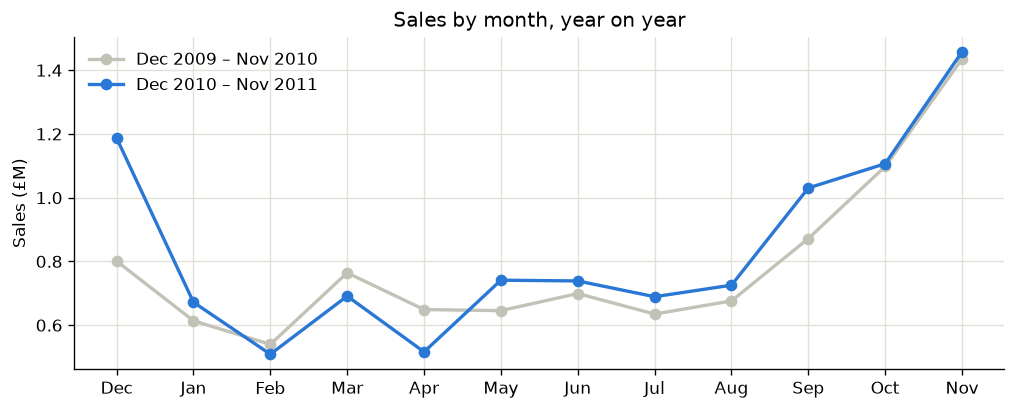

In [5]:
fig, ax = plt.subplots()
for (name, group), colour in zip(complete.groupby("year"), [GREY, BLUE]):
    ax.plot(range(12), group.sales.values / 1e6, marker="o", color=colour, label=name, lw=2)
ax.set_xticks(range(12), ["Dec", "Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov"])
ax.set(ylabel="Sales (£M)", title="Sales by month, year on year")
ax.legend(frameon=False)
plt.show()

Sales grew about 7% while orders fell: the growth is all in bigger orders. September to November is over a third of the year.

## 3. When orders arrive

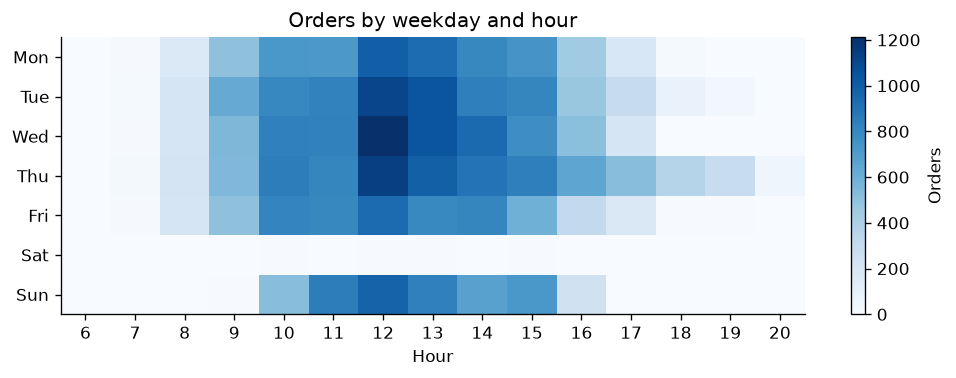

In [6]:
hours = sql("SELECT weekday, hour, orders FROM trading_hours WHERE period = 'all' AND market = 'All markets'")
grid = hours.pivot(index="weekday", columns="hour", values="orders").fillna(0)
fig, ax = plt.subplots(figsize=(10, 3))
image = ax.imshow(grid, cmap="Blues", aspect="auto")
ax.set_yticks(range(len(grid)), ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"][: len(grid)])
ax.set_xticks(range(len(grid.columns)), grid.columns)
ax.set(title="Orders by weekday and hour", xlabel="Hour"); ax.grid(False)
fig.colorbar(image, ax=ax, label="Orders")
plt.show()

Saturday is effectively closed (30 orders in two years), Sunday trades normally, and lunchtime is the peak.

## 4. Customers: RFM segments and retention

In [7]:
segments = sql("""
    SELECT segment, count(*) AS customers, round(sum(monetary)) AS revenue,
           round(100 * sum(monetary) / sum(sum(monetary)) OVER (), 1) AS revenue_pct,
           median(recency_days) AS median_days_since_order, median(frequency) AS median_orders
    FROM customer_rfm GROUP BY 1 ORDER BY revenue DESC
""")
segments

,segment,customers,revenue,revenue_pct,median_days_since_order,median_orders
0,Champions,1508,12378629.0,71.0,17.0,10.0
1,Loyal,564,1933637.0,11.1,93.0,7.0
2,At risk,397,1374279.0,7.9,359.0,5.0
3,Hibernating,1260,801144.0,4.6,405.0,2.0
4,Potential loyalists,682,458584.0,2.6,24.0,2.0
5,Needs attention,620,361180.0,2.1,96.0,2.0
6,Lost,688,105354.0,0.6,477.0,1.0
7,New customers,133,21643.0,0.1,29.0,1.0


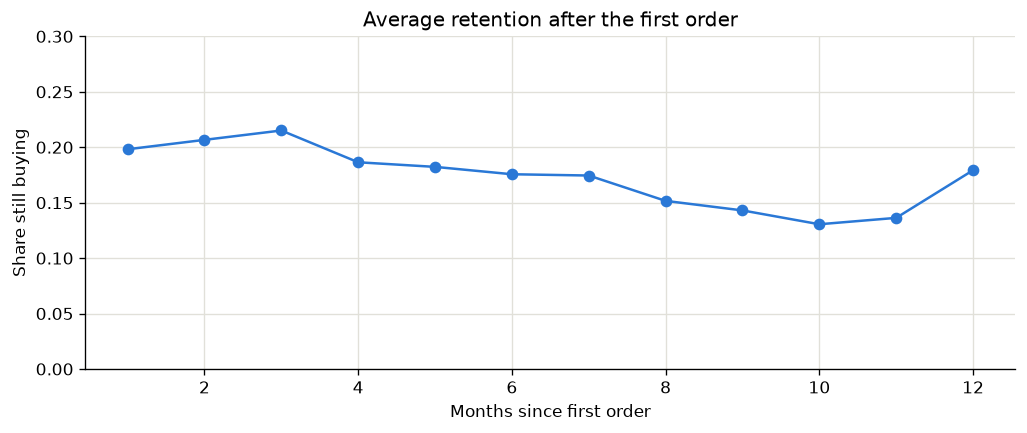

In [8]:
retention = sql("""
    SELECT c.cohort, c.months_since, c.customers / f.customers AS share
    FROM cohort_retention c JOIN cohort_retention f ON f.cohort = c.cohort AND f.months_since = 0
    WHERE c.cohort > '2009-12' AND c.cohort <= '2010-11' AND c.months_since <= 12
""")
curve = retention.groupby("months_since").share.mean().loc[1:12]
ax = curve.plot(marker="o", color=BLUE, title="Average retention after the first order", ylim=(0, 0.3))
ax.set(xlabel="Months since first order", ylabel="Share still buying")
plt.show()

These monthly activity rates use the same mature cohorts. They do not measure the probability of staying after a second purchase.

## 5. Products: concentration, baskets, returns

In [9]:
sql("""
    WITH ranked AS (SELECT sales_gbp, sum(sales_gbp) OVER (ORDER BY sales_gbp DESC) / sum(sales_gbp) OVER () AS cum FROM product_summary)
    SELECT count(*) FILTER (WHERE cum <= 0.8) AS products_for_80pct, count(*) AS all_products FROM ranked
""")

,products_for_80pct,all_products
0,1024,4707


In [10]:
sql("""
    SELECT a.description AS product, b.description AS goes_with, p.together, round(p.lift, 1) AS lift
    FROM basket_pairs p
    JOIN product_summary a ON a.product_id = p.product_a
    JOIN product_summary b ON b.product_id = p.product_b
    WHERE p.together >= 150 ORDER BY p.lift DESC LIMIT 8
""")

,product,goes_with,together,lift
0,PINK POLKADOT CUP,BLUE POLKADOT CUP,521,35.6
1,WOODEN HEART CHRISTMAS SCANDINAVIAN,WOODEN STAR CHRISTMAS SCANDINAVIAN,552,34.1
2,GARDENERS KNEELING PAD CUP OF TEA,GARDENERS KNEELING PAD KEEP CALM,546,31.2
3,SET/6 RED SPOTTY PAPER CUPS,SET/6 RED SPOTTY PAPER PLATES,651,31.0
4,FELTCRAFT CUSHION BUTTERFLY,FELTCRAFT CUSHION RABBIT,491,30.7
5,RED STRIPE CERAMIC DRAWER KNOB,BLUE STRIPE CERAMIC DRAWER KNOB,497,29.6
6,BLUE SPOT CERAMIC DRAWER KNOB,WHITE SPOT BLUE CERAMIC DRAWER KNOB,428,28.9
7,RED RETROSPOT CUP,BLUE POLKADOT CUP,473,26.9


In [11]:
sql("""
    SELECT product_id, units, round(value_gbp) AS value_gbp, invoice_date::DATE AS date
    FROM credits WHERE is_large_credit ORDER BY value_gbp DESC LIMIT 5
""")

,product_id,units,value_gbp,date
0,23843,80995,168470.0,2011-12-09
1,23166,74215,77184.0,2011-01-18
2,21108,3114,6539.0,2011-04-18
3,85123A,1930,4922.0,2011-04-18
4,21175,2000,3700.0,2011-04-18


Large credits are separated by line size. Their cause is unverified; inclusive totals must remain visible.

## 6. Models

Both models are trained and evaluated by the pipeline (`retail/forecast.py`, `retail/recommend.py`). The saved results:

In [12]:
forecast = json.loads((root / "web/data/forecast.json").read_text())
scores = pd.DataFrame(forecast["metrics"]["rows"], columns=forecast["metrics"]["columns"])
print("Chosen on the tuning weeks:", forecast["selected"])
print("80% interval coverage on the holdout:", round(forecast["interval"]["coverage"], 3))
scores.pivot(index="model", columns="window", values="wape").round(3).sort_values("holdout")

Chosen on the tuning weeks: Gradient boosting
80% interval coverage on the holdout: 0.754


window,holdout,tuning
model,,
Gradient boosting,0.464,0.513
4-week average,0.535,0.590
Neural network,0.584,0.642
Last week,0.620,0.654
Same week last year,0.755,0.736


In [13]:
recs = json.loads((root / "web/data/recommendations.json").read_text())
pd.DataFrame(recs["metrics"]["rows"], columns=recs["metrics"]["columns"]).set_index("model").round(3)

,recall_at_10,ndcg_at_10,hit_rate_at_10,catalogue_coverage,customers
model,,,,,
Hybrid (similarity + trending),0.072,0.085,0.436,0.266,1202
Item similarity,0.053,0.063,0.324,0.401,1202
Trending (last 28 days),0.068,0.094,0.429,0.031,1202
Best sellers,0.020,0.030,0.179,0.058,1202


## Takeaways

- Growth came from order value; autumn accounts for a large sales share.
- Customer revenue is concentrated; test a win-back campaign before claiming uplift.
- Compare retention only across equally mature cohorts.
- Product pairings suggest bundle experiments, not causal effects.
- Forecast selection uses a gap before holdout; inspect the current scores above.
- Recommendation metrics are offline; online business impact requires an experiment.
